# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [1]:
team_setup = {
    'team_name': 'DS System Pros',
    'members': [                                  # everyone on the team, 2 to 4 people
        {'name': 'Jennifer Lutchen', 'github': 'https://github.com/Jennifer-Lutchen/ds2002-fa26'},
        {'name': 'Malia Heupel', 'github': 'https://github.com/maliaheupel'},
        {'name': 'Claire Zhang', 'github': 'https://github.com/legsleggylegs/ds2002-fa26'}
    ],
    'repo_url': 'https://github.com/maliaheupel/walmart/tree/main',                           # your main team repo: https://github.com/...
    'charter_url': 'https://github.com/maliaheupel/walmart/blob/main/CHARTER.md',                        # link to CHARTER.md in that repo
    'notebook_owner_this_week': 'Malia Heupel',           # nice to have
    'meeting_time': 'in class',                       # nice to have, e.g. 'Tue and Thu 7pm'
    'five_worst_problems': ['figuring out how to work together in colab','unsure how to handle negative numbers','should we keep rows without a timestamp??','what should we do about SKUs we are uncertain about?'],              # nice to have, five specific problems
}

def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')
    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(real(m['name']) and real(m['github']) for m in t['members']),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md': real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }
    nice = {
        'notebook owner': real(t['notebook_owner_this_week']),
        'meeting time': real(t['meeting_time']),
        'five specific problems': len(t['five_worst_problems']) >= 5 and all(real(p) for p in t['five_worst_problems']),
    }
    if not quiet:
        print('REQUIRED')
        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)
        print('NICE TO HAVE')
        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)
        print()
        print('team setup complete:', all(required.values()))
    return all(required.values())

check_team(team_setup)

REQUIRED
  PASS - team name
  PASS - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  not yet - five specific problems

team setup complete: True


True

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [2]:
import subprocess

REPO_PATH = 'https://github.com/maliaheupel/walmart/tree/main'      # your local clone of the team repo

result = subprocess.run(['git', '-C', REPO_PATH, 'log', '--oneline', '--', 'CHARTER.md'],
                        capture_output=True, text=True)
print(result.stdout.strip() or 'no commits found for CHARTER.md')

no commits found for CHARTER.md


### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [3]:
import pandas as pd
transactions = pd.read_csv("walmart_transactions.csv")

# take a look at the data
print("shape (rows,columns):")
display(transactions.shape)
print("\nhead:")
display(transactions.head())
print("\nData types:")
print(transactions.dtypes)
print("\nMissing values:")
print(transactions.isnull().sum())
print("\nExact duplicates:",transactions.duplicated().sum())

# look at the specific problems
print("Negative quantities:")
display(transactions[transactions['quantity']<0].head())
print("Count:",(transactions['quantity']<0).sum())
print("\nUnit prices containing $:")
display(transactions[transactions['unit_price'].astype(str).str.contains('$',regex=False)].head())
print("Count:",transactions['unit_price'].astype(str).str.contains('$',regex=False).sum())
print("\nStore ID samples:")
print(transactions['store_id'].value_counts().head(20))

# look at the timestamp format
parsed_time = pd.to_datetime(transactions['timestamp'],errors='coerce',format='mixed')
print("Missing before parsing:",transactions['timestamp'].isna().sum())
print("Missing after parsing:", parsed_time.isna().sum())

#build a cleaning function
def clean_transactions(df):
  out = df.drop_duplicates().copy()

  # clean unit prices
  out['unit_price'] = (out['unit_price'].astype(str).str.replace('$','',regex = False).str.strip().astype(float))

  # keep negatives for now and assume they are returns.
  # come back later if that decision changes

  # make timestamps all the same
  out['timestamp'] = pd.to_datetime(out['timestamp'],errors='coerce',format='mixed')

  # standardize store IDs
  out['store_id'] = (out['store_id'].str.upper().str.strip().str.replace(r'[^A-Z0-9]','',regex=True).apply(lambda s: f'{s[:2]}-{s[2:]}'))

  # standardize capitalization and spacing for categories
  out['category'] = (out['category'].str.strip().str.title())

  return out

# find rows affected for store_id and category
clean_store = (transactions['store_id'].str.upper().str.strip().str.replace(r'[^A-Z0-9]', '', regex=True).apply(lambda s: f'{s[:2]}-{s[2:]}'))
print("\nStore IDs changed:", (transactions['store_id'] != clean_store).sum())

clean_category = (transactions['category'].str.strip().str.title())
print("Categories changed:", (transactions['category'] != clean_category).sum())

# run the function and look at the cleaned result
print("\nRows before cleaning:", len(transactions))
cleaned = clean_transactions(transactions)
print("Rows after cleaning:",len(cleaned))
print("Rows removed:", len(transactions)-len(cleaned))




shape (rows,columns):


(25562, 8)


head:


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82



Data types:
transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
category          object
quantity           int64
unit_price        object
dtype: object

Missing values:
transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64

Exact duplicates: 30
Negative quantities:


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
163,TXN008747,FL-078,2024-09-22T21:30:35,PAPERTOWEL6,Paper Towels,HOUSEHOLD,-2,7.91
223,TXN006255,FL-619,2024-09-20 17:10:14,DIAPERS-3,Diapers Size 3,baby,-2,25.79
563,TXN013118,FL-330,09-25-2024 11:32:05,GAME-MONO,Board Game - Monopoly,ENTERTAINMENT,-2,19.58
811,TXN022136,FL-287,09-06-2024 13:20:05,TP-12,TP 12 Pack,household,-2,$9.64
1034,TXN018762,FL-619,2024-09-30 14:42:48,FAID-01,First-Aid Kit,Health,-2,14.45


Count: 130

Unit prices containing $:


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
10,TXN022661,FL-412,2024-09-07 17:22:06,CARDS-01,PLAYING CARDS,entertainment,2,$4.76
11,TXN009801,FL-287,09-23-2024 18:24:47,CHIPVARIETY,Chips Variety Pack,SNACKS,2,$8.75
20,TXN001671,FL-445,2024-09-14T21:52:07,PNUTBTR-16,Peanut Butter,Grocery,2,$3.31
24,TXN006442,FL-710,NaN,PAPERTOWEL6,Paper Towels,Household,1,$7.82
44,TXN007968,FL105,2024-09-22 11:38:37,FLASH-01,FLASHLIGHT LED,EMERGENCY,3,$13.02


Count: 3029

Store ID samples:
store_id
FL-445    1819
FL-156    1808
FL-710    1804
FL-105    1800
FL-412    1787
FL-302    1778
FL-330    1773
FL-287    1749
FL-078    1746
FL-501    1728
FL-239    1727
FL-619    1695
FL_302     151
FL_239     140
FL_619     133
FL_287     131
FL_330     131
FL_445     130
FL_078     127
FL_412     123
Name: count, dtype: int64
Missing before parsing: 886
Missing after parsing: 886

Store IDs changed: 4348
Categories changed: 13175

Rows before cleaning: 25562
Rows after cleaning: 25532
Rows removed: 30


### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [4]:
decision_log = pd.DataFrame([
    {
        'decision': 'remove exact duplicate rows',
        'action':'dropped duplicate rows',
        'rows affected': 30,
        'reason': 'Duplicate rows would double count as sales which is unwanted'
    },
    {
        'decision': 'clean unit_price',
        'action':'standardized formatting by removing all $ and converting prices to a float',
        'rows affected': 3029,
        'reason': 'prices should be numeric for needed calculations'
    },
    {
        'decision': 'keep negative values',
        'action': 'left negative values unchanged',
        'rows affected': 130,
        'reason': 'negative numbers may represent returns which is valuable data that should not be removed'
    },
    {
        'decision': 'keep missing timestamps',
        'action':'standardized valid timestamps, kept rows without them',
        'rows affected': 886,
        'reason': 'For now keep it because the rows may be useful for analysis. future plan is to figure out if these rows are necessary/have important data'
    },
    {
        'decision': 'standardize store IDs',
        'action':'converted IDS to consistent uppercase XX-### format',
        'rows affected': 4348,
        'reason': 'Store IDs need to match across files for joins'
    },
    {
        'decision': 'standardize spacing and capitalization for category',
        'action':'stripped and make everything in the category section into title format',
        'rows affected': 13175,
        'reason': 'This will make it easier for the next steps in cleaning so there are less slight differences'
    },
    {
        'decision': 'dont include certain SKUs in the CANON mapping',
        'action':'left out uncertainties from mapping',
        'rows affected': 10,
        'reason': 'things like the chip variety packs or chargers could be the same or different things, so in the early stages we will keep them separate to be safe'
    }
])
display(decision_log)

,decision,action,rows affected,reason
0,remove exact duplicate rows,dropped duplicate rows,30,Duplicate rows would double count as sales whi...
1,clean unit_price,standardized formatting by removing all $ and ...,3029,prices should be numeric for needed calculations
2,keep negative values,left negative values unchanged,130,negative numbers may represent returns which i...
3,keep missing timestamps,"standardized valid timestamps, kept rows witho...",886,For now keep it because the rows may be useful...
4,standardize store IDs,converted IDS to consistent uppercase XX-### f...,4348,Store IDs need to match across files for joins
5,standardize spacing and capitalization for cat...,stripped and make everything in the category s...,13175,This will make it easier for the next steps in...
6,dont include certain SKUs in the CANON mapping,left out uncertainties from mapping,10,things like the chip variety packs or chargers...


### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [5]:
catalog = pd.read_csv("product_catalog (1).csv")

# inspect the dataset
print("catalog shape:")
display(catalog.shape)
print('\nDistinct SKUs:')
print(catalog['sku'].nunique())

print('\nProduct names:')
display(catalog[['sku','product_name']])

# first standardize all names to get a sense of which names mean the same thing
candidates = catalog.copy()
candidates['name_key'] = (candidates['product_name'].str.lower().str.replace(r'[^a-z0-9\s]',' ',regex=True).str.split().apply(lambda words: ' '.join(sorted(words))))
fragmented = candidates.groupby('name_key').filter(lambda group: group['sku'].nunique() >1)
display(fragmented[['name_key','sku','product_name']].sort_values('name_key'))

# combine same products with different SKUs by mapping
CANON = {
    # poptarts
    'PT-12':'POPTART-STRAW',
    'SKU#459812': 'POPTART-STRAW',
    'POPTART-STRAW': 'POPTART-STRAW',
    'PT_STRAWBERRY':'POPTART-STRAW',

    # water
    'WTR-24': 'WTR-24',
    'WATER24PK':'WTR-24',
    'WTR_24PK': 'WTR-24',

    # batteries
    'BATT-100': 'BAT-AA4',
    'BAT-AA4': 'BAT-AA4',
    'BATT_AA_4PK': 'BAT-AA4',

    # flashlight
    'FLASH-01':'FLASH-01',
    'LED-FLASH':'FLASH-01',

    # beer
    'BEER-24':'BEER-24',
    'LTBEER24': 'BEER-24',

    # monopoly
    'BG-MONO':'MONOPOLY-01',
    'MONOPOLY-01':'MONOPOLY-01',
    'GAME-MONO':'MONOPOLY-01',

    # cards
    'CARDS-01':'CARDS-01',
    'PLAYCARD-STD':'CARDS-01',

    # canned soup
    'SOUP-CAN':'SOUP-CAN',
    'CNSOUP-01':'SOUP-CAN',

    # white bread
    'BREAD-WH':'BREAD-WH',
    'WHITEBREAD':'BREAD-WH',

    # peanut butter
    'PB-16':'PB-16',
    'PNUTBTR-16':'PB-16',

    # Emergency candles
    'CNDL-EM':'CANDLE-EMRG',
    'CANDLE-EMRG':'CANDLE-EMRG',

    # first aid kit
    'FAID-01':'FIRSTAID-KIT',
    'FIRSTAID-KIT':'FIRSTAID-KIT',

    # Paper towels
    'PTOWEL-6':'PTOWEL-6',
    'PAPERTOWEL6':'PTOWEL-6',

    # heavy duty tarp
    'TARP-HD':'TARP-HD',
    'HDTARP-01':'TARP-HD'
}

# apply it
catalog_clean = catalog.copy()
catalog_clean['canonical_sku'] = (catalog_clean['sku'].map(CANON).fillna(catalog_clean['sku']))

# check results
print("Starting distinct SKUs:", catalog['sku'].nunique())
print("Canonical products:", catalog_clean['canonical_sku'].nunique())

group_sizes = (catalog_clean.groupby('canonical_sku').size().sort_values(ascending=False))
print("\nLargest groups:")
display(group_sizes.head())

# show mapping
display(catalog_clean[catalog_clean['sku'].isin(CANON)][['sku','product_name','canonical_sku']].sort_values('canonical_sku'))


catalog shape:


(45, 7)


Distinct SKUs:
45

Product names:


,sku,product_name
0,PT-12,pop-tarts strawberry
1,SKU#459812,Strawberry Pop-Tart
2,POPTART-STRAW,Pop-Tarts Strawberry
3,PT_STRAWBERRY,pop-tarts strawberry
4,WTR-24,BOTTLED WATER 24PK
5,WATER24PK,Bottled Water 24-Pack
6,WTR_24PK,Water - 24 Pack
7,BATT-100,BATTERIES AA 4PK
8,BAT-AA4,AA Batteries 4-Pack
9,BATT_AA_4PK,AA Batteries 4-Pack


,name_key,sku,product_name
12,24 beer light pack,BEER-24,Light Beer (24-pack)
13,24 beer light pack,LTBEER24,Light Beer (24-pack)
8,4 aa batteries pack,BAT-AA4,AA Batteries 4-Pack
9,4 aa batteries pack,BATT_AA_4PK,AA Batteries 4-Pack
30,aid first kit,FIRSTAID-KIT,First Aid Kit
29,aid first kit,FAID-01,First-Aid Kit
15,board game monopoly,MONOPOLY-01,Monopoly Board Game
14,board game monopoly,BG-MONO,Monopoly Board Game
16,board game monopoly,GAME-MONO,Board Game - Monopoly
24,bread white,WHITEBREAD,WHITE BREAD


Starting distinct SKUs: 45
Canonical products: 26

Largest groups:


,0
canonical_sku,
POPTART-STRAW,4
BAT-AA4,3
MONOPOLY-01,3
WTR-24,3
CANDLE-EMRG,2


,sku,product_name,canonical_sku
9,BATT_AA_4PK,AA Batteries 4-Pack,BAT-AA4
8,BAT-AA4,AA Batteries 4-Pack,BAT-AA4
7,BATT-100,BATTERIES AA 4PK,BAT-AA4
13,LTBEER24,Light Beer (24-pack),BEER-24
12,BEER-24,Light Beer (24-pack),BEER-24
24,WHITEBREAD,WHITE BREAD,BREAD-WH
23,BREAD-WH,WHITE BREAD,BREAD-WH
27,CNDL-EM,Candles (Emergency),CANDLE-EMRG
28,CANDLE-EMRG,Emergency Candles,CANDLE-EMRG
18,PLAYCARD-STD,PLAYING CARDS,CARDS-01


### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [6]:
# base off studio
import requests
import time

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start,
        'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)

        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue

        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()

            time.sleep(2 ** attempt)
            continue

        r.raise_for_status()

        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'

        return frame

weather = daily_weather(
    '2024-09-01',
    '2024-09-30'
)

display(weather.head())
print("Weather rows:", len(weather))


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.8,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,22.7,15.2,open-meteo


Weather rows: 30


### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

,date,orders
0,2024-09-01,552
1,2024-09-02,587
2,2024-09-03,582
3,2024-09-04,572
4,2024-09-05,573


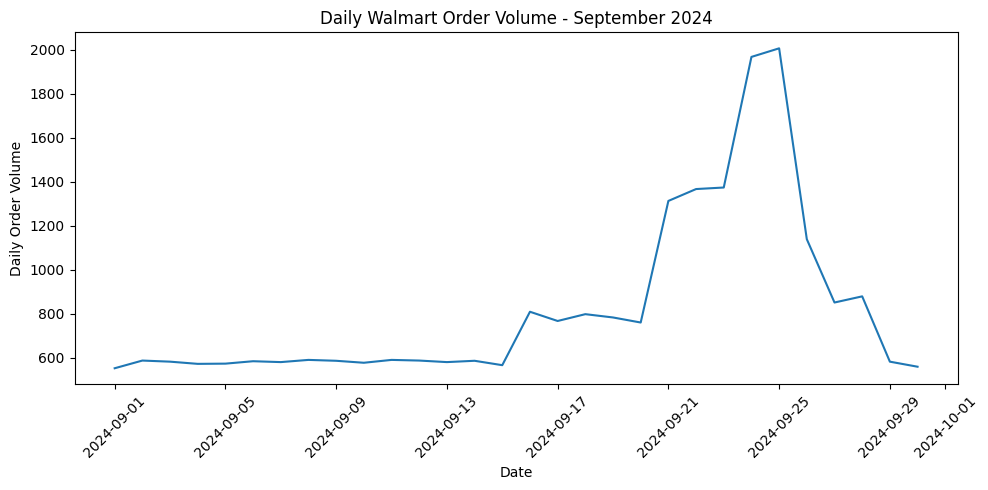

In [7]:
daily_orders = (
    cleaned
    .dropna(subset=['timestamp'])
    .assign(date=lambda x: x['timestamp'].dt.normalize())
    .groupby('date')
    .size()
    .reset_index(name='orders')
)

display(daily_orders.head())

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(daily_orders['date'], daily_orders['orders'])

plt.xlabel('Date')
plt.ylabel('Daily Order Volume')
plt.title('Daily Walmart Order Volume - September 2024')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [8]:
required = {
    'team_setup_complete': check_team(team_setup, quiet=True),   # from the team setup section
    'charter_committed': True,         # TODO: True once CHARTER.md shows in the git log above
}

progress = {
    'rows_after_cleaning': 25532,        # an integer
    'decisions_logged': len(decision_log),           # how many entries in your log
    'canonical_products': 27,         # distinct products after consolidation
    'weather_api_rows': 30,           # rows returned by your API call
    'notebook_runs_clean': True,       # True after Restart and Run All
}

def is_done(value):
    return not (value is None or value is False
                or (isinstance(value, str) and value.startswith('TODO')))

def check(required, progress):
    print('REQUIRED')
    for label, value in required.items():
        print('  PASS' if is_done(value) else '  FAIL', '-', label, '=', value)
    print('PROGRESS (fill in what you have)')
    for label, value in progress.items():
        print('  done' if is_done(value) else '  not yet', '-', label, '=', value)
    ok = all(is_done(v) for v in required.values())
    print()
    print('required items complete:', ok)
    print('progress items done:', sum(is_done(v) for v in progress.values()), 'of', len(progress))
    return ok

check(required, progress)

REQUIRED
  PASS - team_setup_complete = True
  PASS - charter_committed = True
PROGRESS (fill in what you have)
  done - rows_after_cleaning = 25532
  done - decisions_logged = 7
  done - canonical_products = 27
  done - weather_api_rows = 30
  done - notebook_runs_clean = True

required items complete: True
progress items done: 5 of 5


True

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** _..._

**Plan, with an owner and a date:** _..._

### 8 — Where each question stands

**TODO:** mark each of the five questions. These owners must match the question owners table in your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | not started / in progress / draft answer | _..._ |
| Q2 SKU consolidation | _..._ | _..._ |
| Q3 weather correlation | _..._ | _..._ |
| Q4 store and geography | _..._ | _..._ |
| Q5 signal or artifact | _..._ | _..._ |

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.